# Restaurant Tips: A Data Story - CodeAlpha Data Analytics Internship

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", font_scale=1.1)

df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Questions for the restaurant manager
1. Which days and times are busiest?
2. When do we earn the most revenue per table?
3. Does a bigger bill mean a bigger tip?
4. Do tips (as a % of the bill) vary by day or party size?

In [28]:
df["tip_pct"] = (df["tip"] / df["total_bill"] * 100).round(1)

# Put the days in a logical order
day_order = ["Thur", "Fri", "Sat", "Sun"]

df.isnull().sum()   # check for missing values (should be all 0)

,0
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0
tip_pct,0


1. How busy is each day?

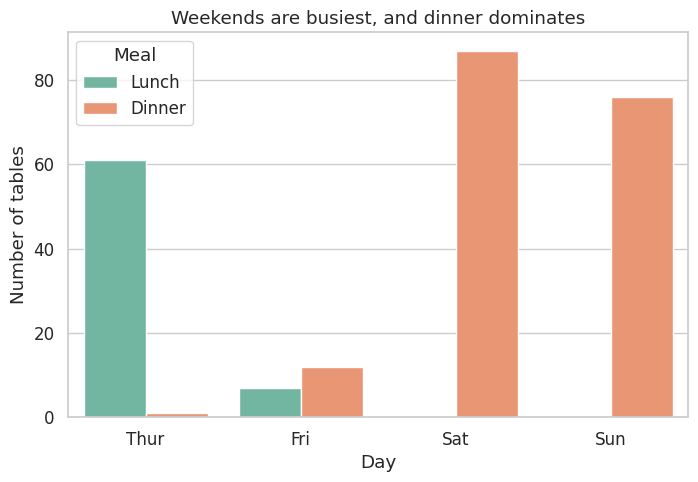

In [29]:
plt.figure(figsize=(8, 5))
sns.countplot(x="day", hue="time", data=df, order=day_order, palette="Set2")
plt.title("Weekends are busiest, and dinner dominates")
plt.xlabel("Day")
plt.ylabel("Number of tables")
plt.legend(title="Meal")
plt.show()

2. Revenue per table by day

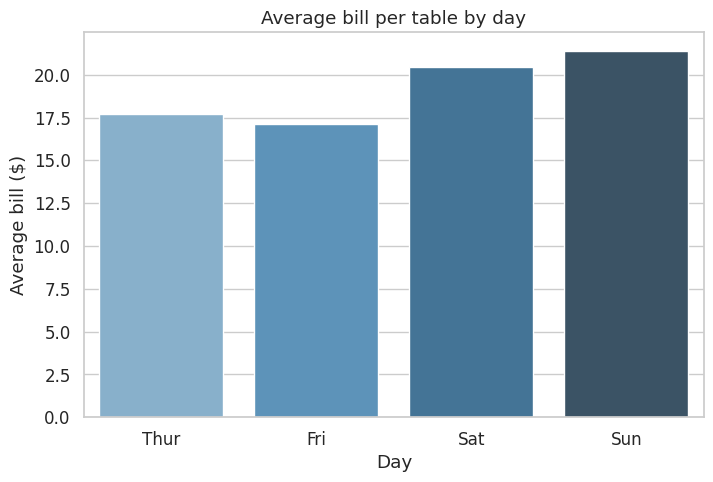

In [30]:
plt.figure(figsize=(8, 5))
sns.barplot(x="day", y="total_bill", hue="day", data=df, order=day_order,
            palette="Blues_d", errorbar=None, legend=False)
plt.title("Average bill per table by day")
plt.xlabel("Day")
plt.ylabel("Average bill ($)")
plt.show()

3. Do bigger bills means bigger tips?

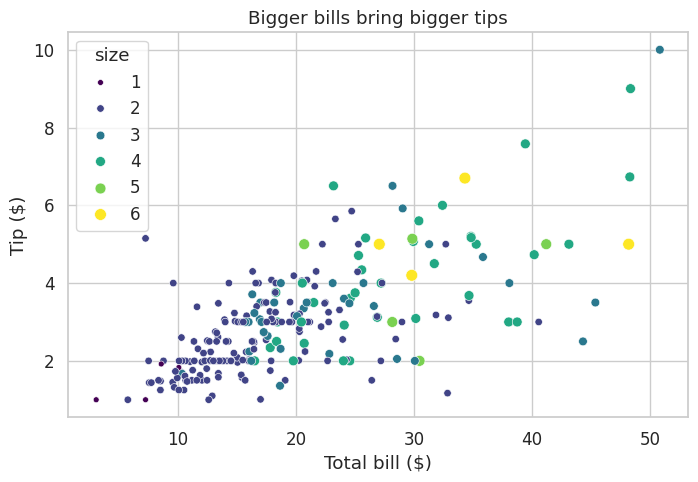

In [31]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="total_bill", y="tip", hue="size", size="size", palette="viridis", data=df)
plt.title("Bigger bills bring bigger tips")
plt.xlabel("Total bill ($)")
plt.ylabel("Tip ($)")
plt.show()

4. Is tipping generous or stingy?

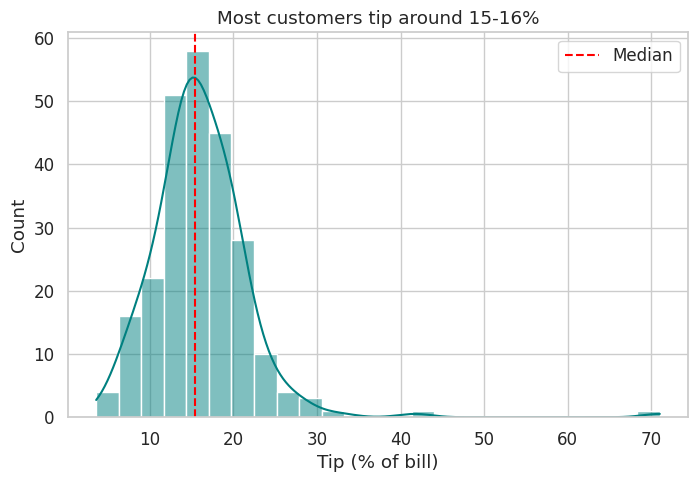

In [32]:
plt.figure(figsize=(8, 5))
sns.histplot(df["tip_pct"], bins=25, kde=True, color="teal")
plt.axvline(df["tip_pct"].median(), color="red", linestyle="--", label="Median")
plt.title("Most customers tip around 15-16%")
plt.xlabel("Tip (% of bill)")
plt.legend()
plt.show()

5. Tip percentage by day

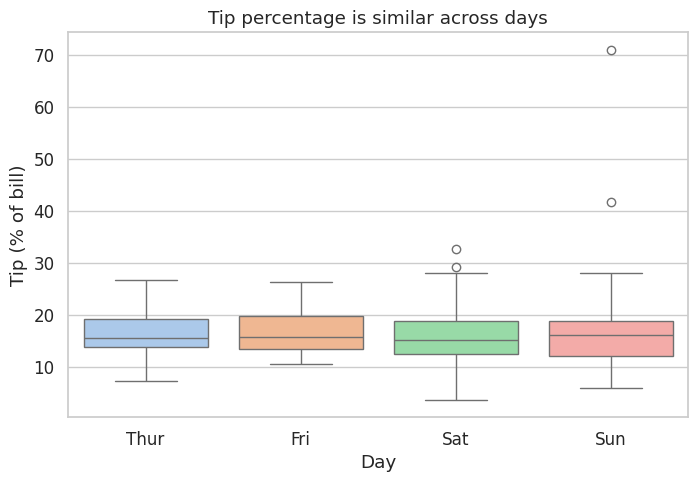

In [33]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="day", y="tip_pct",hue="day", data=df, order=day_order, palette="pastel", legend=False)
plt.title("Tip percentage is similar across days")
plt.xlabel("Day")
plt.ylabel("Tip (% of bill)")
plt.show()

6. Heatmap of average bill by day and meal

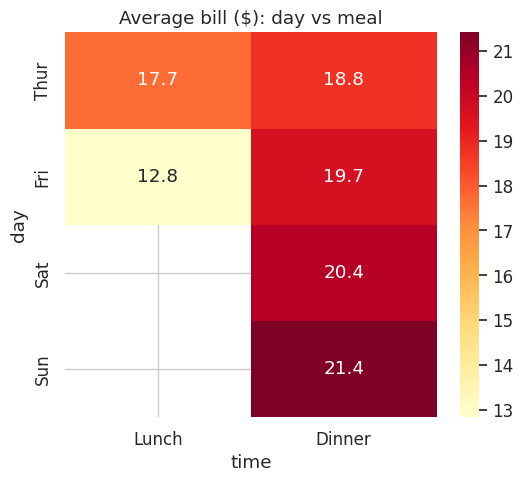

In [34]:
pivot = df.pivot_table(values="total_bill", index="day", columns="time", aggfunc="mean", observed=True)
pivot = pivot.reindex(day_order)

plt.figure(figsize=(6, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Average bill ($): day vs meal")
plt.show()

DASHBOARD

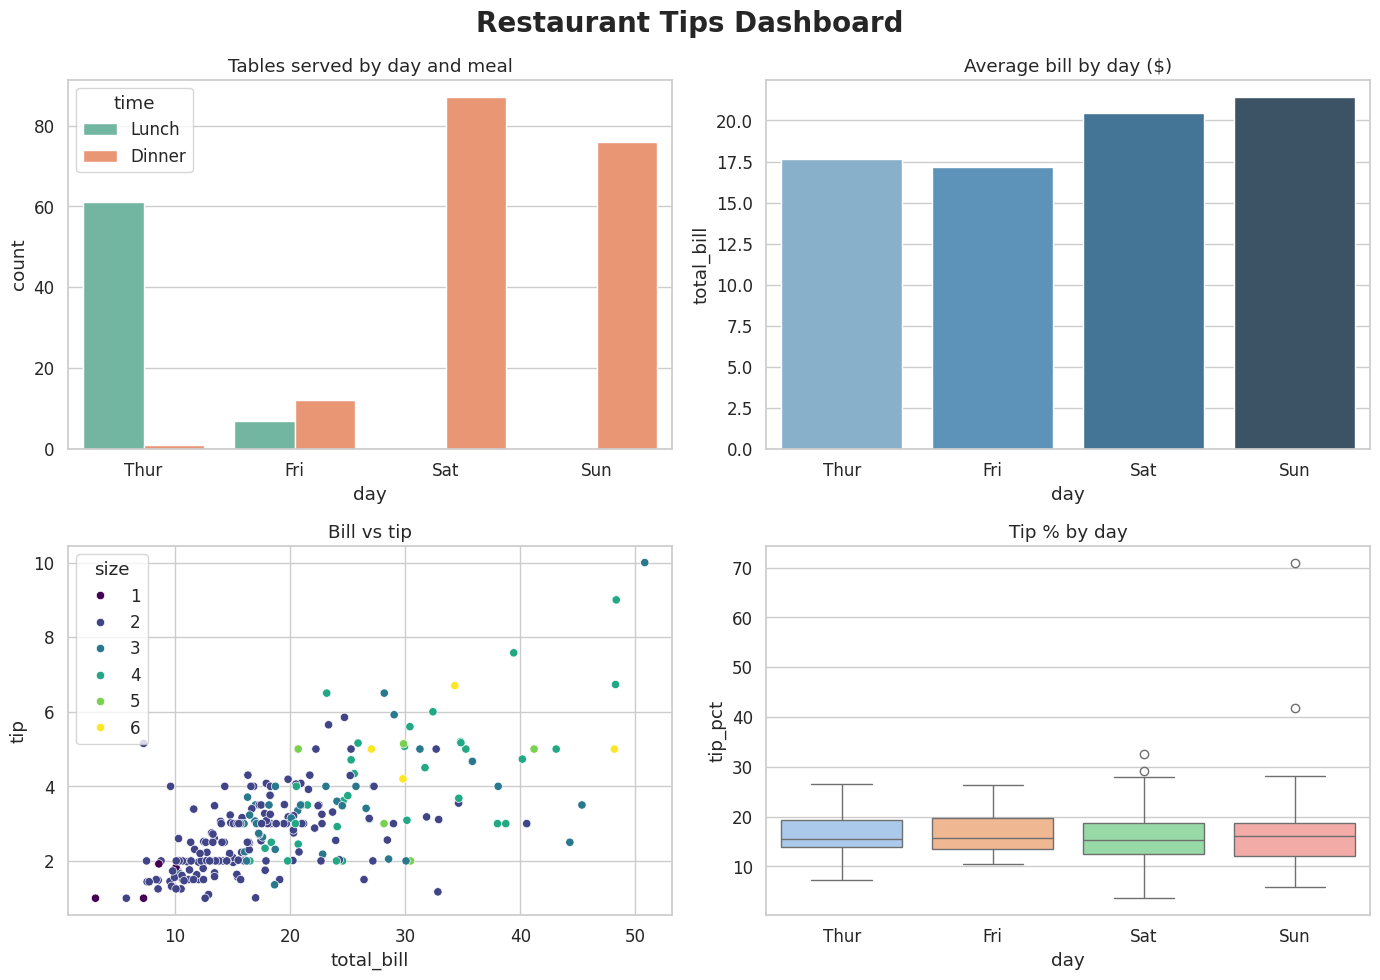

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Restaurant Tips Dashboard", fontsize=20, fontweight="bold")

sns.countplot(x="day", hue="time", data=df, order=day_order, palette="Set2", ax=axes[0, 0])
axes[0, 0].set_title("Tables served by day and meal")

sns.barplot(x="day", y="total_bill", hue="day", data=df, order=day_order,
            palette="Blues_d", errorbar=None, legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Average bill by day ($)")

sns.scatterplot(x="total_bill", y="tip", hue="size", palette="viridis", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Bill vs tip")

sns.boxplot(x="day", y="tip_pct", hue="day", data=df, order=day_order,
            palette="pastel", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Tip % by day")

plt.tight_layout()
plt.savefig("dashboard.png", dpi=150)
plt.show()